In [9]:
# Download about five years of daily prices for all six
import yfinance as yf
import pandas as pd

# Banks: JPMorgan, Bank of America, Wells Fargo
# Mixed industries: Apple for tech, ExxonMobil for energy, Procter & Gamble for household goods
banks = ["BAC", "JPM", "WFC"]
mixed_industries = ["AAPL", "XOM", "PG"]

tickers = banks + mixed_industries

prices = yf.download(tickers, period="5y", auto_adjust=True)["Close"]
returns = prices.pct_change().dropna()

print(prices.shape)
print(returns.head())

[*********************100%***********************]  6 of 6 completed

(1255, 6)
Ticker          AAPL       BAC       JPM        PG       WFC       XOM
Date                                                                  
2021-11-17  0.016490 -0.012107 -0.005382 -0.000611 -0.010522 -0.010920
2021-11-18  0.028536 -0.004085 -0.008634  0.000136  0.001204 -0.010885
2021-11-19  0.016976 -0.019862 -0.013063 -0.002039 -0.021643 -0.046219
2021-11-22  0.002928  0.019383  0.021315  0.006675  0.031135  0.013846
2021-11-23  0.002422  0.026361  0.023912  0.011096  0.021057  0.026337


In [10]:
# mean is just the average daily return of each stock: that’s μ.
print(returns.mean())

# Covariance measures how two stocks move together, but in squared-return units, so the size is hard to read
# σᵢⱼ = E[(Rᵢ − E[Rᵢ]) · (Rⱼ − E[Rⱼ])]
# Pandas Dedault setting σ̂ᵢⱼ = (1 / (T − 1)) · Σₜ₌₁ᵀ (Rᵢ,ₜ − R̄ᵢ)(Rⱼ,ₜ − R̄ⱼ)
print(returns.cov())

Ticker
AAPL    0.000854
BAC     0.000290
JPM     0.000794
PG      0.000300
WFC     0.000689
XOM     0.001025
dtype: float64
Ticker      AAPL       BAC       JPM        PG       WFC       XOM
Ticker                                                            
AAPL    0.000315  0.000114  0.000099  0.000052  0.000113  0.000048
BAC     0.000114  0.000282  0.000207  0.000033  0.000259  0.000078
JPM     0.000099  0.000207  0.000237  0.000032  0.000218  0.000064
PG      0.000052  0.000033  0.000032  0.000137  0.000031  0.000010
WFC     0.000113  0.000259  0.000218  0.000031  0.000347  0.000074
XOM     0.000048  0.000078  0.000064  0.000010  0.000074  0.000283


In [11]:
# "BAC", "JPM", "WFC"
for year in ["2022", "2023", "2024", "2025"]:
    window = returns.loc[year, banks]
    print(year)
    print("cov BAC-JPM:", round(window.cov().loc["BAC", "JPM"], 6))
    print("corr BAC-JPM:", round(window.corr().loc["BAC", "JPM"], 3))
    print()

2022
cov BAC-JPM: 0.000346
corr BAC-JPM: 0.898

2023
cov BAC-JPM: 0.000158
corr BAC-JPM: 0.714

2024
cov BAC-JPM: 0.000159
corr BAC-JPM: 0.749

2025
cov BAC-JPM: 0.000205
corr BAC-JPM: 0.779



In [12]:
# "AAPL", "XOM", "PG"
for year in ["2022", "2023", "2024", "2025"]:
    window = returns.loc[year, mixed_industries]
    print(year)
    print("cov AAPL-XOM:", round(window.cov().loc["AAPL", "XOM"], 6))
    print("corr AAPL-XOM:", round(window.corr().loc["AAPL", "XOM"], 3))
    print("cov AAPL-PG:", round(window.cov().loc["AAPL", "PG"], 6))
    print("corr AAPL-PG:", round(window.corr().loc["AAPL", "PG"], 3))
    print()

2022
cov AAPL-XOM: 0.000138
corr AAPL-XOM: 0.278
cov AAPL-PG: 0.000144
corr AAPL-PG: 0.462

2023
cov AAPL-XOM: 2.5e-05
corr AAPL-XOM: 0.126
cov AAPL-PG: 2.2e-05
corr AAPL-PG: 0.187

2024
cov AAPL-XOM: -6e-06
corr AAPL-XOM: -0.036
cov AAPL-PG: -4e-06
corr AAPL-PG: -0.03

2025
cov AAPL-XOM: 0.000115
corr AAPL-XOM: 0.381
cov AAPL-PG: 5.7e-05
corr AAPL-PG: 0.232



In [15]:
# Portfolio variance (Markowitz 1952, p. 81)
import numpy as np

# V = Σᵢ Σⱼ σᵢⱼ Xᵢ Xⱼ
def portfolio_variance_loop(cov, w):
    V = 0.0
    
    for i in range(len(w)):
        for j in range(len(w)):
            V += cov[i, j] * w[i] * w[j]
    return V

# Matrix form: V = Xᵀ Σ X
for name, group in [("banks", banks), ("mixed", mixed_industries)]:
    cov = returns[group].cov().values
    w = np.array([1/3, 1/3, 1/3])
    V_loop = portfolio_variance_loop(cov, w)
    V_matrix = w @ cov @ w
    
    print(name, "V loop:", round(V_loop, 7),
        "V matrix:", round(V_matrix, 7),
        "daily vol:", round(np.sqrt(V_matrix), 4))

banks V loop: 0.0002483 V matrix: 0.0002483 daily vol: 0.0158
mixed V loop: 0.000106 V matrix: 0.000106 daily vol: 0.0103


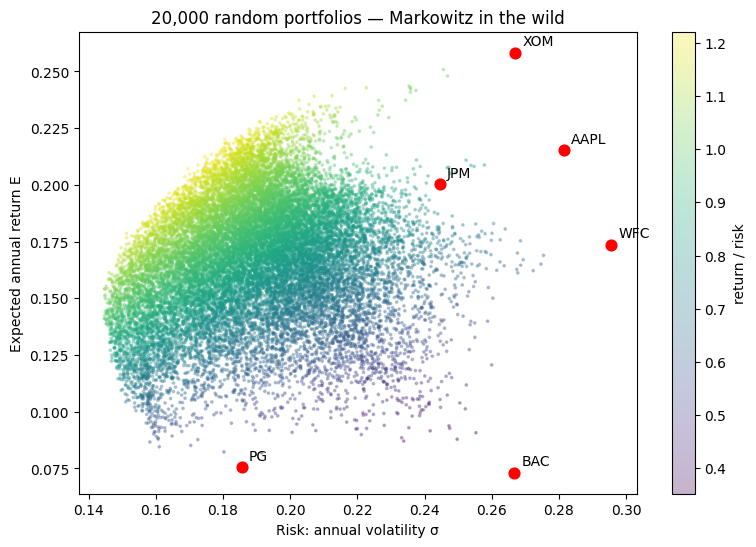

In [16]:
import numpy as np
import matplotlib.pyplot as plt

tickers = returns.columns
mu = returns.mean().values * 252 # annualized expected returns
cov = returns.cov().values * 252 # annualized covariance matrix

n_portfolios = 20_000
rng = np.random.default_rng(42)
W = rng.dirichlet(np.ones(len(tickers)), n_portfolios) # weights >= 0, sum to 1

E = W @ mu # Σ Xᵢ μᵢ for each portfolio
V = np.einsum("pi,ij,pj->p", W, cov, W) # Σᵢ Σⱼ σᵢⱼ Xᵢ Xⱼ for each
vol = np.sqrt(V)

plt.figure(figsize=(9, 6))
plt.scatter(vol, E, s=3, alpha=0.3, c=E / vol, cmap="viridis")
plt.colorbar(label="return / risk")

for k, t in enumerate(tickers):
    plt.scatter(np.sqrt(cov[k, k]), mu[k], color="red", s=60)
    plt.annotate(t, (np.sqrt(cov[k, k]), mu[k]),
                xytext=(5, 5), textcoords="offset points")

plt.xlabel("Risk: annual volatility σ")
plt.ylabel("Expected annual return E")
plt.title("20,000 random portfolios — Markowitz in the wild")
plt.show()

In [17]:
# Find Minimum Variance Portfolio
from scipy.optimize import minimize

n = len(tickers)
x0 = np.ones(n) / n                                   # start from equal weights

result = minimize(
    lambda w: w @ cov @ w,                            # V = Xᵀ Σ X
    x0,
    method="SLSQP",
    bounds=[(0, 1)] * n,                              # Xᵢ ≥ 0, no short sales
    constraints={"type": "eq", "fun": lambda w: w.sum() - 1},  # Σ Xᵢ = 1
)

w_min = result.x
print(pd.Series(w_min.round(3), index=tickers))
print("return:", round(w_min @ mu, 3), " risk:", round(np.sqrt(w_min @ cov @ w_min), 3))

Ticker
AAPL    0.087
BAC     0.011
JPM     0.173
PG      0.513
WFC     0.001
XOM     0.215
dtype: float64
return: 0.149  risk: 0.144


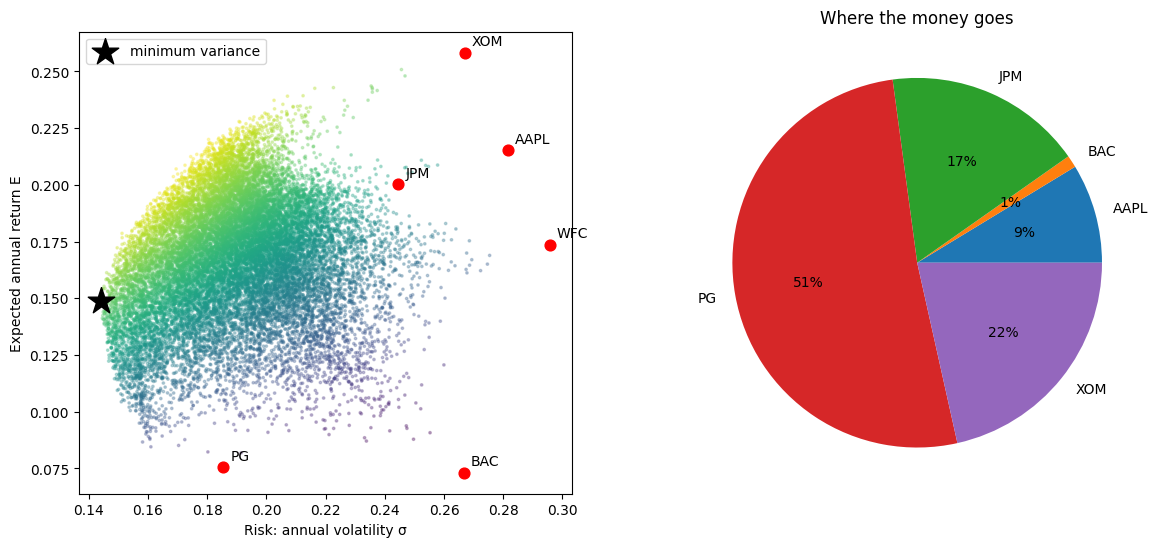

In [18]:
# Depict Minimum Variance Portfolio

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.scatter(vol, E, s=3, alpha=0.3, c=E / vol, cmap="viridis")
for k, t in enumerate(tickers):
    ax1.scatter(np.sqrt(cov[k, k]), mu[k], color="red", s=60)
    ax1.annotate(t, (np.sqrt(cov[k, k]), mu[k]), xytext=(5, 5), textcoords="offset points")
ax1.scatter(np.sqrt(w_min @ cov @ w_min), w_min @ mu,
            marker="*", s=400, color="black", label="minimum variance")
ax1.set_xlabel("Risk: annual volatility σ")
ax1.set_ylabel("Expected annual return E")
ax1.legend()

keep = w_min > 0.01
ax2.pie(w_min[keep], labels=tickers[keep], autopct="%1.0f%%")
ax2.set_title("Where the money goes")
plt.show()